In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

import os
FIGDIR = "results/eda_visualizations"
os.makedirs(FIGDIR, exist_ok=True)

GLU = pd.read_csv("results/outputs/diabetes_glucose.csv")
print("loaded:", GLU.shape)
GLU.head()

loaded: (13511, 31)


,patient_id,timestamp,date,time,hour,time_of_day,day_of_week,is_weekend,reading_index,code,context,code_description,glucose_mg_dl,prev_glucose,prev_glucose_2,glucose_change,hours_since_prev,hours_to_next,rolling_mean_3,rolling_std_3,insulin_regular_6h,insulin_nph_6h,insulin_ultralente_6h,total_insulin_6h,daily_total_insulin,meals_6h,exercise_6h,hypo_symptoms_6h,risk_class,next_glucose,next_risk_class
0,1,1991-04-21 09:09:00,1991-04-21,09:09,9,morning,Sunday,True,1,58,pre_breakfast,Pre-breakfast blood glucose,100.0,NaN,NaN,NaN,NaN,7.983333,100.000000,NaN,9.0,13.0,0.0,22.0,29.0,0,0,0,Normal,119.0,Normal
1,1,1991-04-21 17:08:00,1991-04-21,17:08,17,afternoon,Sunday,True,2,62,pre_supper,Pre-supper blood glucose,119.0,100.0,NaN,19.0,7.983333,5.716667,109.500000,13.435029,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,123.0,Normal
2,1,1991-04-21 22:51:00,1991-04-21,22:51,22,night_late,Sunday,True,3,48,unspecified,Unspecified blood glucose measurement,123.0,119.0,100.0,4.0,5.716667,8.733333,114.000000,12.288206,7.0,0.0,0.0,7.0,29.0,0,0,0,Normal,216.0,Hyperglycemic
3,1,1991-04-22 07:35:00,1991-04-22,07:35,7,morning,Monday,False,4,58,pre_breakfast,Pre-breakfast blood glucose,216.0,123.0,119.0,93.0,8.733333,9.350000,152.666667,54.884728,10.0,13.0,0.0,23.0,32.0,0,0,0,Hyperglycemic,211.0,Hyperglycemic
4,1,1991-04-22 16:56:00,1991-04-22,16:56,16,afternoon,Monday,False,5,62,pre_supper,Pre-supper blood glucose,211.0,216.0,123.0,-5.0,9.350000,14.483333,183.333333,52.309974,9.0,0.0,0.0,9.0,32.0,0,0,0,Hyperglycemic,257.0,Hyperglycemic


In [21]:
GLU_clean = GLU.dropna(subset=["prev_glucose", "next_glucose"])\
               .drop(columns=["prev_glucose_2"]).copy()
print("working rows:", len(GLU_clean))



working rows: 13371


In [14]:
q1, q3 = GLU_clean.glucose_mg_dl.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f"Q1 = {q1:.1f}   Q3 = {q3:.1f}   IQR = {iqr:.1f}")
print(f"IQR bounds: {lo:.1f} to {hi:.1f} mg/dL")

flagged = GLU_clean[(GLU_clean.glucose_mg_dl < lo) | (GLU_clean.glucose_mg_dl > hi)]
print("\nrows IQR would remove:", len(flagged))
print("\nby risk class:")
print(flagged.risk_class.value_counts())

Q1 = 97.0   Q3 = 209.0   IQR = 112.0
IQR bounds: -71.0 to 377.0 mg/dL

rows IQR would remove: 142

by risk class:
risk_class
Hyperglycemic    142
Name: count, dtype: int64


In [24]:
print("range of flagged values:",
      flagged.glucose_mg_dl.min(), "to", flagged.glucose_mg_dl.max())
print("as % of all Hyperglycemic rows:",
      f"{len(flagged)/(GLU_clean.risk_class=='Hyperglycemic').sum()*100:.1f}%")
print("\ndistinct patients affected:", flagged.patient_id.nunique(), "of 70")
print("\ntop contributors:")
print(flagged.patient_id.value_counts().head(5))


range of flagged values: 378.0 to 499.0
as % of all Hyperglycemic rows: 3.0%

distinct patients affected: 38 of 70

top contributors:
patient_id
67    22
20    13
70    11
56     9
61     7
Name: count, dtype: int64


### Why the glucose IQR outliers are kept, not removed

The 1.5×IQR rule flags every `glucose_mg_dl` reading above the IQR upper bound
as statistically unusual — but checking `risk_class` on those flagged rows
(above) shows they are **all genuine Hyperglycemic readings** (glucose > 180
mg/dL), not data-entry errors. For an insulin-dependent diabetes patient, a
high reading is real clinical signal, not noise, and it is exactly the kind of
event the downstream classifier is meant to detect. Removing them would delete
real Hyperglycemic cases and bias the model toward under-predicting risk, so
IQR-based trimming is rejected for this column.

In [25]:
for col in ["hours_since_prev", "total_insulin_6h", "daily_total_insulin"]:
    c_q1, c_q3 = GLU_clean[col].quantile([0.25, 0.75])
    c_iqr = c_q3 - c_q1
    c_lo, c_hi = c_q1 - 1.5*c_iqr, c_q3 + 1.5*c_iqr
    n = ((GLU_clean[col] < c_lo) | (GLU_clean[col] > c_hi)).sum()
    print(f"{col:22s} bounds {c_lo:8.1f} to {c_hi:8.1f}   flagged: {n:5d}")
    print(f"{'':22s} actual range {GLU_clean[col].min():.1f} to {GLU_clean[col].max():.1f}\n")

hours_since_prev       bounds     -3.4 to     16.4   flagged:   463
                       actual range 0.0 to 729.0

total_insulin_6h       bounds    -33.0 to     55.0   flagged:   200
                       actual range 0.0 to 80.0

daily_total_insulin    bounds     -1.0 to     71.0   flagged:   656
                       actual range 0.0 to 129.0



In [17]:
for cutoff in [24, 48, 72, 168]:
    n = (GLU_clean.hours_since_prev > cutoff).sum()
    print(f"gaps > {cutoff:4d} h ({cutoff//24:2d} days): {n:5d} rows ({n/len(GLU_clean)*100:.2f}%)")

gaps >   24 h ( 1 days):   332 rows (2.48%)
gaps >   48 h ( 2 days):    77 rows (0.58%)
gaps >   72 h ( 3 days):    44 rows (0.33%)
gaps >  168 h ( 7 days):    18 rows (0.13%)


### The real outlier being removed: time gaps, not glucose values

Instead, this notebook removes rows where the **gap since the previous
reading** (`hours_since_prev`) is abnormally large. The distribution is
heavily right-skewed: most gaps are a few hours (typical self-monitoring
cadence), but a small number stretch out to days or weeks (max = 729h ≈ 30
days). A gap that large means the "previous reading" lag features
(`prev_glucose`, `glucose_change`, `rolling_std_3`, etc.) are being computed
across a multi-day blind spot, so they no longer reflect a meaningful
short-term trend — that is the real outlier for this dataset, not the glucose
value itself.

The cutoff sweep above shows **48h** removes only 77 rows (0.58%) while
still keeping every gap of 2 days or less, which comfortably covers normal
day-to-day monitoring gaps (e.g. a patient skipping an evening reading).

In [18]:
CUTOFF = 48
GLU_out = GLU_clean[GLU_clean.hours_since_prev <= CUTOFF].copy()

print("rows before:", len(GLU_clean))
print("rows after: ", len(GLU_out))
print("removed:    ", len(GLU_clean) - len(GLU_out),
      f"({(len(GLU_clean)-len(GLU_out))/len(GLU_clean)*100:.2f}%)")
print("\nrisk class after:")
print(GLU_out.risk_class.value_counts())

rows before: 13371
rows after:  13294
removed:     77 (0.58%)

risk class after:
risk_class
Normal           6949
Hyperglycemic    4787
Hypoglycemic     1558
Name: count, dtype: int64


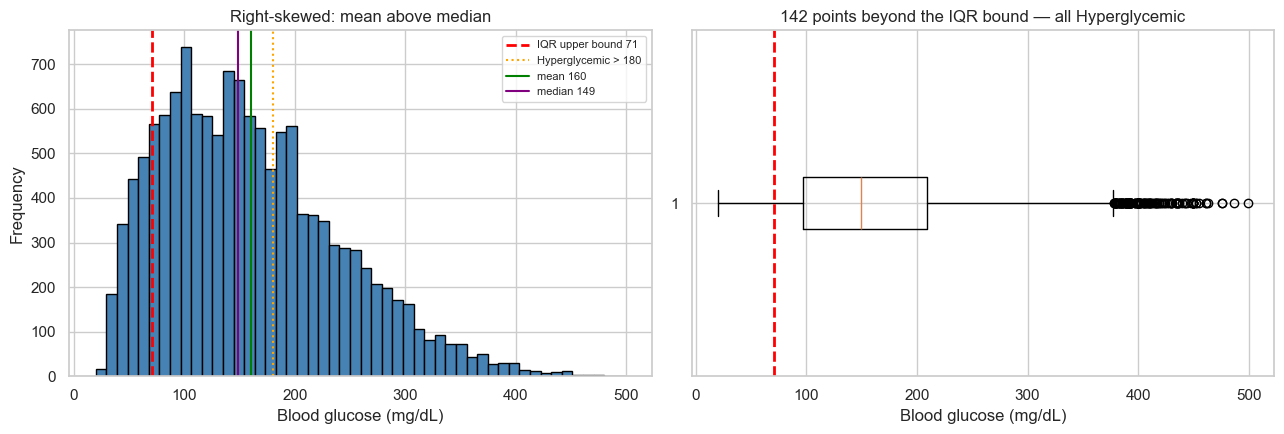

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(GLU_clean.glucose_mg_dl, bins=50, edgecolor="black", color="steelblue")
axes[0].axvline(hi, color="red", linestyle="--", lw=2, label=f"IQR upper bound {hi:.0f}")
axes[0].axvline(180, color="orange", linestyle=":", label="Hyperglycemic > 180")
axes[0].axvline(GLU_clean.glucose_mg_dl.mean(), color="green",
                label=f"mean {GLU_clean.glucose_mg_dl.mean():.0f}")
axes[0].axvline(GLU_clean.glucose_mg_dl.median(), color="purple",
                label=f"median {GLU_clean.glucose_mg_dl.median():.0f}")
axes[0].set_xlabel("Blood glucose (mg/dL)"); axes[0].set_ylabel("Frequency")
axes[0].set_title("Right-skewed: mean above median")
axes[0].legend(fontsize=8)

axes[1].boxplot(GLU_clean.glucose_mg_dl, vert=False)
axes[1].axvline(hi, color="red", linestyle="--", lw=2)
axes[1].set_xlabel("Blood glucose (mg/dL)")
axes[1].set_title(f"{len(flagged)} points beyond the IQR bound — all Hyperglycemic")

plt.tight_layout()
plt.savefig(f"{FIGDIR}/outlier_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

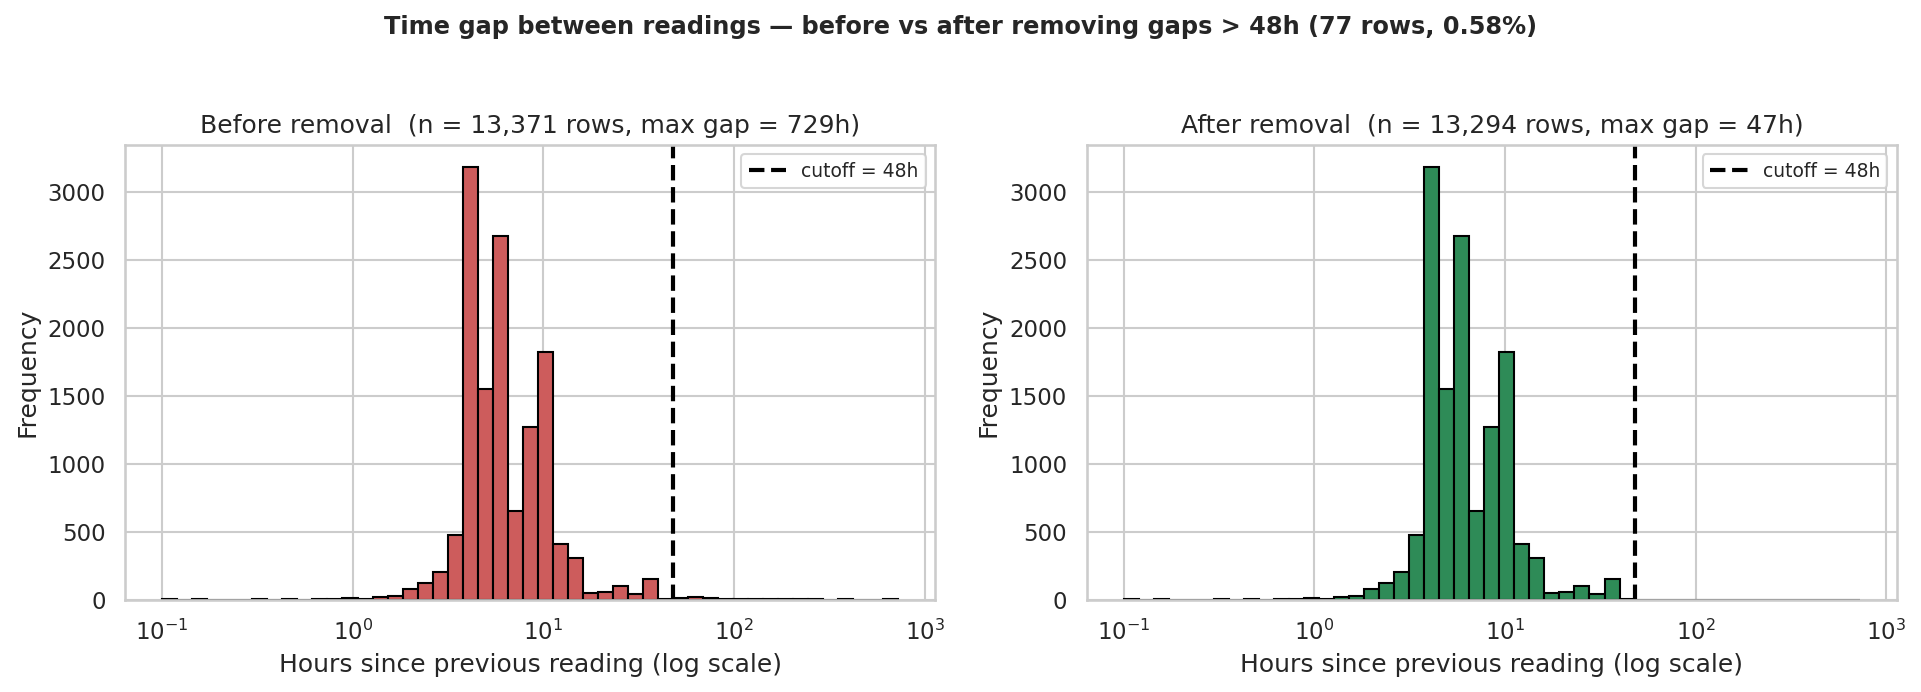

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bins = np.logspace(np.log10(0.1), np.log10(GLU_clean.hours_since_prev.max()), 50)

axes[0].hist(GLU_clean.hours_since_prev, bins=bins, color="indianred", edgecolor="black")
axes[0].axvline(CUTOFF, color="black", linestyle="--", lw=2, label=f"cutoff = {CUTOFF}h")
axes[0].set_xscale("log")
axes[0].set_xlabel("Hours since previous reading (log scale)")
axes[0].set_ylabel("Frequency")
axes[0].set_title(f"Before removal  (n = {len(GLU_clean):,} rows, max gap = {GLU_clean.hours_since_prev.max():.0f}h)")
axes[0].legend(fontsize=9)

axes[1].hist(GLU_out.hours_since_prev, bins=bins, color="seagreen", edgecolor="black")
axes[1].axvline(CUTOFF, color="black", linestyle="--", lw=2, label=f"cutoff = {CUTOFF}h")
axes[1].set_xscale("log")
axes[1].set_xlabel("Hours since previous reading (log scale)")
axes[1].set_ylabel("Frequency")
axes[1].set_title(f"After removal  (n = {len(GLU_out):,} rows, max gap = {GLU_out.hours_since_prev.max():.0f}h)")
axes[1].legend(fontsize=9)

fig.suptitle(f"Time gap between readings — before vs after removing gaps > {CUTOFF}h "
             f"({len(GLU_clean)-len(GLU_out)} rows, {(len(GLU_clean)-len(GLU_out))/len(GLU_clean)*100:.2f}%)",
             fontsize=11.5, fontweight="bold", y=1.03)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/time_gap_outlier_before_after.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
GLU_out.to_csv("results/outputs/03_outliers_handled.csv", index=False)
print("saved:", GLU_out.shape)

saved: (13294, 30)
